In [1]:
import pandas as pd
from pathlib import Path

# Load Week-5 model results
project_path = Path("..")

predictions_path = project_path / "data" / "processed" / "week5_test_predictions.csv"
comparison_path = project_path / "data" / "processed" / "week5_model_comparison.csv"

predictions = pd.read_csv(predictions_path)
comparison = pd.read_csv(comparison_path)

print("Test predictions shape:", predictions.shape)
print("\nPrediction columns:")
print(predictions.columns.tolist())

print("\nFirst 5 predictions:")
display(predictions.head())

print("\nModel comparison:")
display(comparison)

Test predictions shape: (138689, 3)

Prediction columns:
['actual_rating', 'multinomial_naive_bayes_prediction', 'logistic_regression_prediction']

First 5 predictions:


,actual_rating,multinomial_naive_bayes_prediction,logistic_regression_prediction
0,5,5,5
1,5,5,5
2,1,1,1
3,5,5,5
4,1,1,1



Model comparison:


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Multinomial Naive Bayes,0.707655,0.520400,0.378670,0.372669
1,Logistic Regression,0.726518,0.511134,0.437938,0.441833


In [2]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = predictions["actual_rating"]

model_columns = {
    "Multinomial Naive Bayes": "multinomial_naive_bayes_prediction",
    "Logistic Regression": "logistic_regression_prediction"
}

evaluation_results = []

for model_name, column in model_columns.items():
    y_pred = predictions[column]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Evaluation metrics calculated from saved test predictions:")
display(evaluation_df)

Evaluation metrics calculated from saved test predictions:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Multinomial Naive Bayes,0.707655,0.520400,0.378670,0.372669
1,Logistic Regression,0.726518,0.511134,0.437938,0.441833


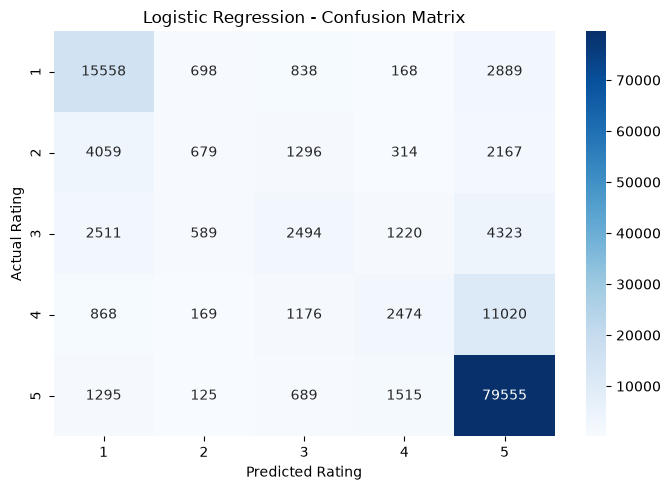

Classification Report - Logistic Regression
              precision    recall  f1-score   support

           1       0.64      0.77      0.70     20151
           2       0.30      0.08      0.13      8515
           3       0.38      0.22      0.28     11137
           4       0.43      0.16      0.23     15707
           5       0.80      0.96      0.87     83179

    accuracy                           0.73    138689
   macro avg       0.51      0.44      0.44    138689
weighted avg       0.67      0.73      0.68    138689



In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path

# Actual and predicted ratings for Logistic Regression
y_true = predictions["actual_rating"]
y_pred = predictions["logistic_regression_prediction"]

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4, 5])

# Display confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.tight_layout()
plt.show()

# Print classification report
print("Classification Report - Logistic Regression")
print(classification_report(y_true, y_pred, labels=[1, 2, 3, 4, 5], zero_division=0))

In [4]:
print("Actual test records:", len(y_true))
print("Predicted test records:", len(y_pred))
print("Confusion matrix total:", cm.sum())
print("Classification report support total:", sum(
    classification_report(
        y_true,
        y_pred,
        labels=[1, 2, 3, 4, 5],
        output_dict=True,
        zero_division=0
    )[str(i)]["support"]
    for i in [1, 2, 3, 4, 5]
))

Actual test records: 138689
Predicted test records: 138689
Confusion matrix total: 138689
Classification report support total: 138689.0


In [5]:
print("Predictions DataFrame shape:", predictions.shape)
print("Actual ratings count:", len(predictions["actual_rating"]))
print("Naive Bayes predictions:", len(predictions["multinomial_naive_bayes_prediction"]))
print("Logistic Regression predictions:", len(predictions["logistic_regression_prediction"]))

print("\nRating counts:")
print(predictions["actual_rating"].value_counts().sort_index())

Predictions DataFrame shape: (138689, 3)
Actual ratings count: 138689
Naive Bayes predictions: 138689
Logistic Regression predictions: 138689

Rating counts:
actual_rating
1    20151
2     8515
3    11137
4    15707
5    83179
Name: count, dtype: int64


In [6]:
import pandas as pd
from pathlib import Path

predictions_path = Path("../data/processed/week5_test_predictions.csv")

fresh_predictions = pd.read_csv(predictions_path)

print("CSV path:", predictions_path.resolve())
print("Fresh CSV shape:", fresh_predictions.shape)
print("Total actual ratings:", fresh_predictions["actual_rating"].count())

print("\nActual rating counts:")
print(fresh_predictions["actual_rating"].value_counts().sort_index())

print("\nFirst 5 rows:")
display(fresh_predictions.head())

CSV path: C:\Users\amits\OneDrive\Desktop\Beauty-Wellness-Data-Science\data\processed\week5_test_predictions.csv
Fresh CSV shape: (138689, 3)
Total actual ratings: 138689

Actual rating counts:
actual_rating
1    20151
2     8515
3    11137
4    15707
5    83179
Name: count, dtype: int64

First 5 rows:


,actual_rating,multinomial_naive_bayes_prediction,logistic_regression_prediction
0,5,5,5
1,5,5,5
2,1,1,1
3,5,5,5
4,1,1,1


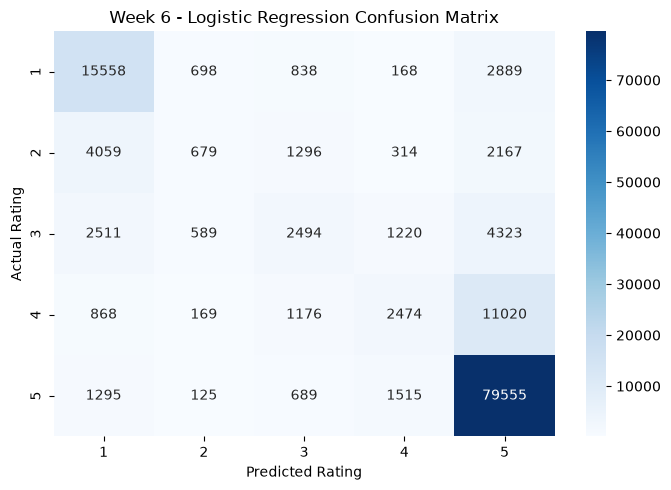

Week-6 evaluation files saved successfully!
Evaluation metrics: C:\Users\amits\OneDrive\Desktop\Beauty-Wellness-Data-Science\data\processed\week6_evaluation_metrics.csv
Classification report: C:\Users\amits\OneDrive\Desktop\Beauty-Wellness-Data-Science\data\processed\week6_logistic_regression_classification_report.json
Confusion matrix: C:\Users\amits\OneDrive\Desktop\Beauty-Wellness-Data-Science\visuals\week6_confusion_matrix.png
Test records evaluated: 138689
Confusion matrix total: 138689


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Logistic Regression,0.726518,0.511134,0.437938,0.441833


In [7]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the freshly loaded Week-5 predictions
df_eval = fresh_predictions.copy()

y_true = df_eval["actual_rating"]
y_pred = df_eval["logistic_regression_prediction"]

# Calculate final metrics
metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "Macro F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0)
}

metrics_df = pd.DataFrame([metrics])

# Project output folders
project_root = Path("..")
processed_dir = project_root / "data" / "processed"
visuals_dir = project_root / "visuals"

processed_dir.mkdir(parents=True, exist_ok=True)
visuals_dir.mkdir(parents=True, exist_ok=True)

# Save metrics CSV
metrics_path = processed_dir / "week6_evaluation_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

# Save classification report JSON
report = classification_report(
    y_true,
    y_pred,
    labels=[1, 2, 3, 4, 5],
    output_dict=True,
    zero_division=0
)

report_path = processed_dir / "week6_logistic_regression_classification_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

# Save confusion matrix image
cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)
plt.title("Week 6 - Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.tight_layout()

confusion_path = visuals_dir / "week6_confusion_matrix.png"
plt.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Week-6 evaluation files saved successfully!")
print("Evaluation metrics:", metrics_path.resolve())
print("Classification report:", report_path.resolve())
print("Confusion matrix:", confusion_path.resolve())
print("Test records evaluated:", len(y_true))
print("Confusion matrix total:", cm.sum())

display(metrics_df)

In [8]:
print("Confusion matrix:")
print(cm)

print("\nRow totals:", cm.sum(axis=1))
print("Column totals:", cm.sum(axis=0))
print("Matrix total:", cm.sum())
print("Actual records:", len(y_true))

Confusion matrix:
[[15558   698   838   168  2889]
 [ 4059   679  1296   314  2167]
 [ 2511   589  2494  1220  4323]
 [  868   169  1176  2474 11020]
 [ 1295   125   689  1515 79555]]

Row totals: [20151  8515 11137 15707 83179]
Column totals: [24291  2260  6493  5691 99954]
Matrix total: 138689
Actual records: 138689
